# ACO: five-city tour from your notes
Find a short tour through **A, B, C, D, E**, visiting every city once and returning to the start. Distances are symmetric.

We reproduce **one complete iteration**, with three ants starting from A, B, and C and using the tours written in the notes. Probabilities are computed accurately rather than copying the rounded arithmetic errors.

Run the cells in order. Only NumPy and Matplotlib are required.

## 1. Import the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 2. Enter the distance matrix
The diagonal is zero because a city has no distance to itself.

In [2]:
cities = np.array(["A", "B", "C", "D", "E"])
distance = np.array([
    [0, 2, 9, 10, 7],
    [2, 0, 6, 4, 3],
    [9, 6, 0, 8, 9],
    [10, 4, 8, 0, 5],
    [7, 3, 9, 5, 0]
], dtype=float)

def show_matrix(matrix, title):
    print(title)
    print("      " + "".join(f"{city:>9}" for city in cities))
    for city, row in zip(cities, matrix):
        print(f"{city:>5} " + "".join(f"{value:9.4f}" for value in row))

show_matrix(distance, "Distances")

Distances
              A        B        C        D        E
    A    0.0000   2.0000   9.0000  10.0000   7.0000
    B    2.0000   0.0000   6.0000   4.0000   3.0000
    C    9.0000   6.0000   0.0000   8.0000   9.0000
    D   10.0000   4.0000   8.0000   0.0000   5.0000
    E    7.0000   3.0000   9.0000   5.0000   0.0000


## 3. Set the parameters from the notes
α controls pheromone influence, β controls distance preference, ρ is evaporation, and Q scales the deposit.

In [3]:
alpha = 1
beta = 2
rho = 0.5
Q = 100
start_cities = [0, 1, 2]
pheromone = np.ones_like(distance)
np.fill_diagonal(pheromone, 0)
show_matrix(pheromone, "Initial pheromone")

Initial pheromone
              A        B        C        D        E
    A    0.0000   1.0000   1.0000   1.0000   1.0000
    B    1.0000   0.0000   1.0000   1.0000   1.0000
    C    1.0000   1.0000   0.0000   1.0000   1.0000
    D    1.0000   1.0000   1.0000   0.0000   1.0000
    E    1.0000   1.0000   1.0000   1.0000   0.0000


## 4. Calculate desirability
$$\eta_{ij}=1/d_{ij}$$
Shorter edges have greater desirability. Set the diagonal to zero to avoid dividing by zero.

In [4]:
eta = np.zeros_like(distance)
np.divide(1.0, distance, out=eta, where=distance > 0)
show_matrix(eta, "Desirability: eta")
show_matrix(eta**beta, "Squared desirability: eta^2")

Desirability: eta
              A        B        C        D        E
    A    0.0000   0.5000   0.1111   0.1000   0.1429
    B    0.5000   0.0000   0.1667   0.2500   0.3333
    C    0.1111   0.1667   0.0000   0.1250   0.1111
    D    0.1000   0.2500   0.1250   0.0000   0.2000
    E    0.1429   0.3333   0.1111   0.2000   0.0000
Squared desirability: eta^2
              A        B        C        D        E
    A    0.0000   0.2500   0.0123   0.0100   0.0204
    B    0.2500   0.0000   0.0278   0.0625   0.1111
    C    0.0123   0.0278   0.0000   0.0156   0.0123
    D    0.0100   0.0625   0.0156   0.0000   0.0400
    E    0.0204   0.1111   0.0123   0.0400   0.0000


## 5. Calculate transition probabilities
An ant can move only to an unvisited city.
$$p_{ij}=\frac{\tau_{ij}^{\alpha}\eta_{ij}^{\beta}}{\sum_{h\in\mathrm{unvisited}}\tau_{ih}^{\alpha}\eta_{ih}^{\beta}}$$
The denominator changes after each move. Returning to the starting city happens only after all cities have been visited.

In [5]:
def transition_probabilities(current, unvisited, pheromone):
    weights = pheromone[current, unvisited]**alpha * eta[current, unvisited]**beta
    return weights / weights.sum()

def show_choices(current, unvisited, pheromone):
    weights = pheromone[current, unvisited]**alpha * eta[current, unvisited]**beta
    probabilities = transition_probabilities(current, unvisited, pheromone)
    print(f"From {cities[current]} | denominator = {weights.sum():.6f}")
    for target, weight, probability in zip(unvisited, weights, probabilities):
        print(f"  {cities[current]} → {cities[target]}: weight = {weight:.6f}, p = {probability:.6f}")
    return probabilities

## 6. First move of the ant starting at A
All pheromones are 1, so the weights are simply 1 / distance².

**Arithmetic correction:** the A–D weight is 1/10² = **0.01**, giving a total of about **0.292754**. Thus P(A→B) is about **0.85396**.

In [6]:
probabilities_A = show_choices(0, [1, 2, 3, 4], pheromone)

From A | denominator = 0.292754
  A → B: weight = 0.250000, p = 0.853960
  A → C: weight = 0.012346, p = 0.042171
  A → D: weight = 0.010000, p = 0.034158
  A → E: weight = 0.020408, p = 0.069711


## 7. First move of the ant starting at B

In [7]:
probabilities_B = show_choices(1, [0, 2, 3, 4], pheromone)

From B | denominator = 0.451389
  B → A: weight = 0.250000, p = 0.553846
  B → C: weight = 0.027778, p = 0.061538
  B → D: weight = 0.062500, p = 0.138462
  B → E: weight = 0.111111, p = 0.246154


## 8. First move of the ant starting at C
Use the same formula; the precise values differ slightly from the rounded values in the notes.

In [8]:
probabilities_C = show_choices(2, [0, 1, 3, 4], pheromone)

From C | denominator = 0.068094
  C → A: weight = 0.012346, p = 0.181303
  C → B: weight = 0.027778, p = 0.407932
  C → D: weight = 0.015625, p = 0.229462
  C → E: weight = 0.012346, p = 0.181303


## 9. Enter the three tours shown in the notes
These are **given sampled tours**, entered explicitly to reproduce the worked example. A general ACO program samples each next city using the transition probabilities; choosing the largest probability every time would be a different rule.

In [9]:
tours = [
    [0, 1, 4, 3, 2, 0],
    [1, 0, 4, 3, 2, 1],
    [2, 1, 0, 4, 3, 2]
]

for ant, tour in enumerate(tours, start=1):
    print(f"Ant {ant}: " + " → ".join(cities[tour]))

Ant 1: A → B → E → D → C → A
Ant 2: B → A → E → D → C → B
Ant 3: C → B → A → E → D → C


## 10. Follow every move step by step
Recalculate probabilities using only the remaining cities. All three ants use the initial pheromone; updates happen after all tours are complete.

In [10]:
for ant, tour in enumerate(tours, start=1):
    print(f"\nANT {ant}")
    visited = {tour[0]}
    for current, next_city in zip(tour[:-2], tour[1:-1]):
        unvisited = [i for i in range(len(cities)) if i not in visited]
        show_choices(current, unvisited, pheromone)
        print(f"  Given move: {cities[current]} → {cities[next_city]}")
        visited.add(next_city)
    print(f"Return: {cities[tour[-2]]} → {cities[tour[-1]]}")


ANT 1
From A | denominator = 0.292754
  A → B: weight = 0.250000, p = 0.853960
  A → C: weight = 0.012346, p = 0.042171
  A → D: weight = 0.010000, p = 0.034158
  A → E: weight = 0.020408, p = 0.069711
  Given move: A → B
From B | denominator = 0.201389
  B → C: weight = 0.027778, p = 0.137931
  B → D: weight = 0.062500, p = 0.310345
  B → E: weight = 0.111111, p = 0.551724
  Given move: B → E
From E | denominator = 0.052346
  E → C: weight = 0.012346, p = 0.235849
  E → D: weight = 0.040000, p = 0.764151
  Given move: E → D
From D | denominator = 0.015625
  D → C: weight = 0.015625, p = 1.000000
  Given move: D → C
Return: C → A

ANT 2
From B | denominator = 0.451389
  B → A: weight = 0.250000, p = 0.553846
  B → C: weight = 0.027778, p = 0.061538
  B → D: weight = 0.062500, p = 0.138462
  B → E: weight = 0.111111, p = 0.246154
  Given move: B → A
From A | denominator = 0.042754
  A → C: weight = 0.012346, p = 0.288762
  A → D: weight = 0.010000, p = 0.233897
  A → E: weight = 0.0204

## 11. Calculate each tour length
$$L_k=\sum_{(i,j)\in\mathrm{tour}_k}d_{ij}$$
Include the final edge back to the start.

In [11]:
lengths = []
for ant, tour in enumerate(tours, start=1):
    edge_lengths = distance[tour[:-1], tour[1:]]
    length = edge_lengths.sum()
    lengths.append(length)
    calculation = " + ".join(f"{value:g}" for value in edge_lengths)
    print(f"Ant {ant}: {calculation} = {length:g}")
lengths = np.array(lengths)

Ant 1: 2 + 3 + 5 + 8 + 9 = 27
Ant 2: 2 + 7 + 5 + 8 + 6 = 28
Ant 3: 6 + 2 + 7 + 5 + 8 = 28


## 12. Calculate each ant's pheromone reward
$$\Delta\tau_{ij}^{(k)}=\begin{cases}Q/L_k & \text{if ant }k\text{ uses edge }(i,j)\\0 & \text{otherwise}\end{cases}$$
An ant deposits this amount on **each edge it used**, including its return edge. Shorter tours earn larger deposits.

In [12]:
rewards = Q / lengths
for ant, (length, reward) in enumerate(zip(lengths, rewards), start=1):
    print(f"Ant {ant}: Q/L = {Q}/{length:g} = {reward:.6f}")

Ant 1: Q/L = 100/27 = 3.703704
Ant 2: Q/L = 100/28 = 3.571429
Ant 3: Q/L = 100/28 = 3.571429


## 13. Add deposits from all ants
$$\Delta\tau_{ij}=\sum_k\Delta\tau_{ij}^{(k)}$$
Because distances are symmetric, an edge receives the same deposit in both directions. Edges unused by every ant receive zero.

In [13]:
deposits = np.zeros_like(distance)
for tour, reward in zip(tours, rewards):
    for i, j in zip(tour[:-1], tour[1:]):
        deposits[i, j] += reward
        deposits[j, i] += reward

show_matrix(deposits, "Total deposit on every edge")

Total deposit on every edge
              A        B        C        D        E
    A    0.0000  10.8466   3.7037   0.0000   7.1429
    B   10.8466   0.0000   7.1429   0.0000   3.7037
    C    3.7037   7.1429   0.0000  10.8466   0.0000
    D    0.0000   0.0000  10.8466   0.0000  10.8466
    E    7.1429   3.7037   0.0000  10.8466   0.0000


## 14. Evaporate the old pheromone
$$\tau_{ij}^{\mathrm{evaporated}}=(1-\rho)\tau_{ij}$$
Every valid edge starts at 1, so after 50% evaporation it has 0.5.

In [14]:
evaporated = (1 - rho) * pheromone
show_matrix(evaporated, "Pheromone after evaporation")

Pheromone after evaporation
              A        B        C        D        E
    A    0.0000   0.5000   0.5000   0.5000   0.5000
    B    0.5000   0.0000   0.5000   0.5000   0.5000
    C    0.5000   0.5000   0.0000   0.5000   0.5000
    D    0.5000   0.5000   0.5000   0.0000   0.5000
    E    0.5000   0.5000   0.5000   0.5000   0.0000


## 15. Apply the pheromone update
$$\tau_{ij}^{\mathrm{new}}=(1-\rho)\tau_{ij}+\Delta\tau_{ij}$$
This is the **new pheromone**, not the deposit alone. Keep full precision until printing.

In [15]:
updated_pheromone = evaporated + deposits
show_matrix(updated_pheromone, "Updated pheromone after iteration 1")

print("\nEdge-by-edge calculation")
for i in range(len(cities)):
    for j in range(i + 1, len(cities)):
        print(f"{cities[i]}{cities[j]}: {evaporated[i, j]:.4f} + {deposits[i, j]:.4f} = {updated_pheromone[i, j]:.4f}")

Updated pheromone after iteration 1
              A        B        C        D        E
    A    0.0000  11.3466   4.2037   0.5000   7.6429
    B   11.3466   0.0000   7.6429   0.5000   4.2037
    C    4.2037   7.6429   0.0000  11.3466   0.5000
    D    0.5000   0.5000  11.3466   0.0000  11.3466
    E    7.6429   4.2037   0.5000  11.3466   0.0000

Edge-by-edge calculation
AB: 0.5000 + 10.8466 = 11.3466
AC: 0.5000 + 3.7037 = 4.2037
AD: 0.5000 + 0.0000 = 0.5000
AE: 0.5000 + 7.1429 = 7.6429
BC: 0.5000 + 7.1429 = 7.6429
BD: 0.5000 + 0.0000 = 0.5000
BE: 0.5000 + 3.7037 = 4.2037
CD: 0.5000 + 10.8466 = 11.3466
CE: 0.5000 + 0.0000 = 0.5000
DE: 0.5000 + 10.8466 = 11.3466


## 16. See how the next iteration changes
Compare the first move from A before and after updating pheromone. Edges rewarded by the ants now influence the next choices.

A → B: 0.853960 → 0.930194
A → C: 0.042171 → 0.017018
A → D: 0.034158 → 0.001640
A → E: 0.069711 → 0.051148


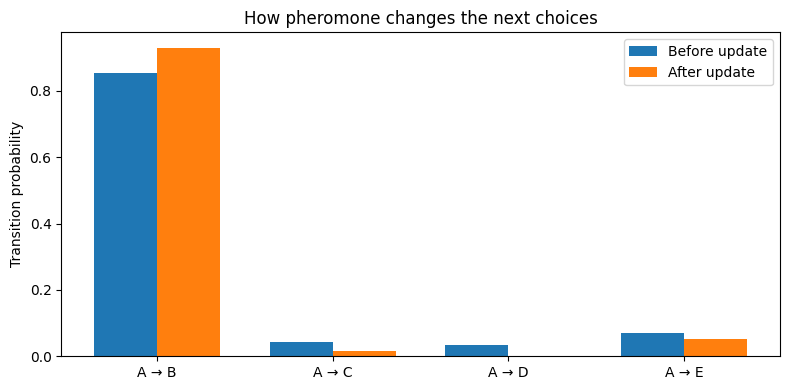

In [16]:
before = transition_probabilities(0, [1, 2, 3, 4], pheromone)
after = transition_probabilities(0, [1, 2, 3, 4], updated_pheromone)
for city, old, new in zip(cities[1:], before, after):
    print(f"A → {city}: {old:.6f} → {new:.6f}")

positions = np.arange(4)
plt.figure(figsize=(8, 4))
plt.bar(positions - 0.18, before, width=0.36, label="Before update")
plt.bar(positions + 0.18, after, width=0.36, label="After update")
plt.xticks(positions, [f"A → {city}" for city in cities[1:]])
plt.ylabel("Transition probability")
plt.title("How pheromone changes the next choices")
plt.legend()
plt.tight_layout()
plt.show()

## 17. Report the best tour in this iteration
This is the best of the three given tours; a single iteration does not establish the globally shortest tour.

In [17]:
best_ant = np.argmin(lengths)
print("Best tour: " + " → ".join(cities[tours[best_ant]]))
print(f"Tour length: {lengths[best_ant]:g}")

Best tour: A → B → E → D → C → A
Tour length: 27


### Expected results
- Tour lengths: **27, 28, 28**.
- Per-ant deposits: **3.703704, 3.571429, 3.571429**.
- Updated AB and CD: **11.346561** each.
- Updated BE and AC: **4.203704** each.
- Updated AE and BC: **7.642857** each.
- Updated DE: **11.346561**.
- Unused AD, BD, CE: **0.5** each.

To continue ACO, use the updated pheromone to sample three new tours, then repeat the length, reward, evaporation, and update steps.